# Number theory 1: Divisibility and primes

*Learning path: number theory, part 1 of 6.* [Index](README.md) · Next: [Prime factoring](02-prime-factoring.ipynb)

Number theory studies the whole numbers $1, 2, 3, \ldots$ For two thousand years it was the purest of pure
mathematics; since the 1970s it is what keeps every bank transfer and every web page secret. This path builds up to
that: lesson 2 is about splitting numbers into primes, lesson 3 about splitting them with algebra, lesson 4 about
computing with remainders, lesson 5 about cryptography. In this lesson you will learn

* division with remainder and what "divides" means,
* the greatest common divisor and **Euclid's algorithm**, the oldest algorithm still in daily use,
* why there are infinitely many primes,
* how the primes thin out (the **prime number theorem**), and how irregular the gaps between them are,
* the **fundamental theorem of arithmetic**, and what it tells you about divisors and perfect numbers.

You only need the [Numbers](../foundations/01-numbers.ipynb) lesson of the foundations path.

## 1. Division with remainder

Any whole number $a$ can be divided by $b > 0$ as $a = q\cdot b + r$ with a **quotient** $q$ and a **remainder**
$0 \le r < b$. `floor(a/b)` is the quotient (the fraction rounded down) and `mod(a, b)` the remainder:

In [1]:
floor(100/7)
mod(100, 7)
14*7 + 2

14
2
100

We say $b$ **divides** $a$, written $b \mid a$, when the remainder is 0. `divisors(n)` lists every divisor of $n$:

In [2]:
divisors(60)
divisors(97)

1	2	3	4	5	6	10	12	15	20	30	60
1	97

60 has twelve divisors, which is why it was the Babylonian base of counting and survives in 60 minutes and 360
degrees. 97 has only two: it is **prime**.

## 2. The greatest common divisor

The **greatest common divisor** $\gcd(a, b)$ is the largest number dividing both $a$ and $b$. Listing all divisors
works for small numbers but not for large ones. Euclid (around 300 BC) noticed that a common divisor of $a$ and $b$
also divides the remainder $a - qb$, so

$$\gcd(a, b) = \gcd(b, \operatorname{mod}(a, b)),$$

and the numbers get smaller at every step until the remainder is 0. Euclid's own example is $\gcd(1071, 462)$:

In [3]:
mod(1071, 462)
mod(462, 147)
mod(147, 21)

147
21
0

So $\gcd(1071, 462) = \gcd(462, 147) = \gcd(147, 21) = \gcd(21, 0) = 21$. We can teach Galileo the algorithm as a
**recursive function**: a function that calls itself with smaller numbers. `if(condition, a, b)` gives $a$ when the
condition holds and $b$ otherwise; `==` tests whether two things are equal:

In [4]:
euclid(a, b) := if(b == 0, a, euclid(b, mod(a, b)));
euclid(1071, 462)
euclid(2^60 - 1, 2^40 - 1)
gcd(2^60 - 1, 2^40 - 1)

21
1048575
1048575

The built-in `gcd` gives the same answers. Even for numbers with hundreds of digits Euclid's algorithm needs only a few
hundred steps, because the remainders at least halve every two steps.

The gcd can always be written as a combination of $a$ and $b$ (**Bézout's identity**): $21 = -3\cdot 1071 + 7\cdot 462$.
This will matter for dividing with remainders in lesson 4.

In [5]:
-3*1071 + 7*462

21

The **least common multiple** is $\operatorname{lcm}(a, b) = ab/\gcd(a, b)$: two gears with 12 and 18 teeth line up
again after $\operatorname{lcm}(12, 18) = 36$ teeth.

In [6]:
lcm(12, 18)

36

## 3. There are infinitely many primes

A **prime** is a whole number above 1 whose only divisors are 1 and itself. The first ones are found with the
**sieve of Eratosthenes**: write down $2, 3, 4, \ldots, n$, circle 2 and cross out its multiples, circle the next
number not crossed out (3) and cross out its multiples, and so on. What is circled are the primes. `primes(n)` runs
the sieve up to $n$:

In [7]:
primes(100)

2	3	5	7	11	13	17	19	23	29	31	37	41	43	47	53	59	61	67	71	73	79	83	89	97

Euclid's proof that the list never ends: suppose $p_1, \ldots, p_k$ were all the primes. The number
$N = p_1 p_2 \cdots p_k + 1$ leaves remainder 1 when divided by each of them, so its prime factors are new primes. Try
it with the first six primes:

In [8]:
N = 2*3*5*7*11*13 + 1
mod(N, 13)
factor(N)

30031
1
59 * 509

$N = 30031$ is not prime itself, but its prime factors 59 and 509 are not on the list. Whatever finite list you start
with, there is always a prime missing.

## 4. How the primes thin out

`primepi(x)` counts the primes up to $x$ (the usual name for this count is $\pi(x)$, nothing to do with
$\pi = 3.14\ldots$). Among the first 100 numbers a quarter are prime; further out they get rarer:

In [9]:
primepi(100)
primepi(10000)
primepi(10^7)

25
1229
664579

Gauss, at 15, guessed that near $x$ about one number in $\log x$ is prime ($\log$ is the natural logarithm), so that
$\pi(x) \approx x/\log x$. This is the **prime number theorem**, proved in 1896 by Hadamard and de la Vallée Poussin.

The plot checks it up to 1000. First a table: `table(expr, k, a, b)` computes `expr` for $k = a, \ldots, b$, one row each.
Here each row is $[n, \pi(n)]$ for $n = 10k$. `scatter(T, [n p])` draws one point per row; `[n p]` names the two
columns, the first across and the second up. `plot(n/log(n), n, 10, 1000)` draws Gauss's estimate as a curve for $n$
from 10 to 1000, and `show` puts both in one picture:

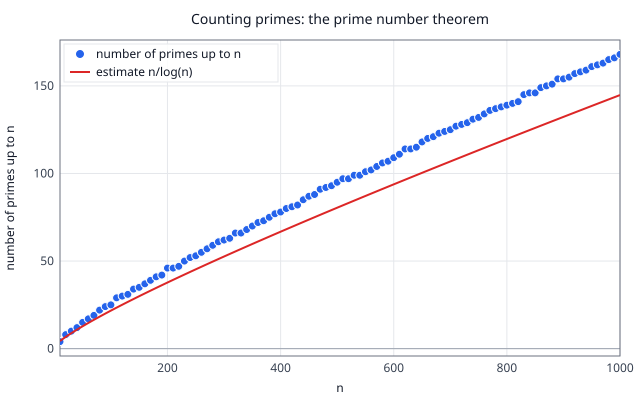

In [10]:
T = table([10*k, primepi(10*k)], k, 1, 100);
p = show(scatter(T, [n p]), plot(n/log(n), n, 10, 1000));
p = legend(p, "number of primes up to n", "estimate n/log(n)");
labels(title(p, "Counting primes: the prime number theorem"), "n", "number of primes up to n")

Each point shows how many primes there are up to $n$. The estimate has the right shape but is about 15% too low here.
The table below compares them at $10, 100, \ldots, 10^7$: the columns are $n$, $\pi(n)$, $n/\log n$, and their ratio.
The ratio creeps towards 1, but slowly (`eval` turns an exact expression into a decimal):

In [11]:
table([10^k, primepi(10^k), eval(10^k/log(10^k)), eval(primepi(10^k)*log(10^k)/10^k)], k, 1, 7)

10	4	4.3429448190325175	0.9210340371976184
100	25	21.714724095162588	1.151292546497023
1000	168	144.76482730108393	1.160502886868999
10000	1229	1085.7362047581294	1.1319508317158729
100000	9592	8685.889638065035	1.1043198105999446
1000000	78498	72382.41365054196	1.0844899477790797
10000000	664579	620420.6884332169	1.071174788961823

### Gaps between primes

On average the gap after a prime $p$ is about $\log p$, but individual gaps jump around. `prime(k)` is the $k$-th
prime. The plot has one point per prime: across is the prime $p$, up is the gap to the next prime.

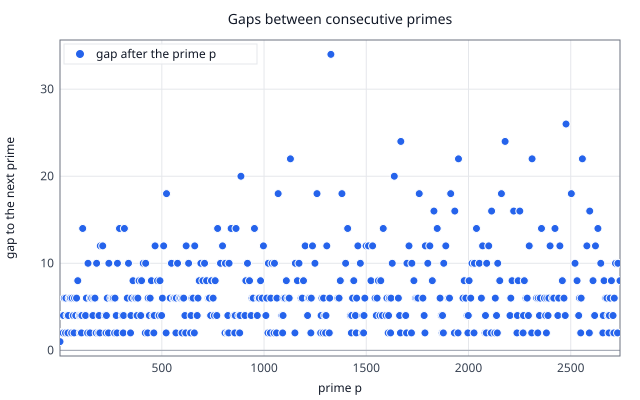

In [12]:
G = table([prime(k), prime(k + 1) - prime(k)], k, 1, 400);
labels(title(legend(scatter(G, [p gap]), "gap after the prime p"), "Gaps between consecutive primes"), "prime p", "gap to the next prime")

All gaps after the first are even (every prime after 2 is odd). The bottom row of points at height 2 are the **twin
primes** like 11 and 13, or 2711 and 2713. Nobody knows whether there are infinitely many twin primes; in 2013 Yitang
Zhang proved that some gap below 70 million occurs infinitely often, and that bound is now down to 246. Large gaps
exist too: none of the 99 numbers $100! + 2, \ldots, 100! + 100$ is prime, since $100! + k$ is divisible by $k$.

## 5. The fundamental theorem of arithmetic

Every whole number above 1 is a product of primes, and the primes and their powers are the same whichever way you
find them. `factor(n)` writes $n$ as that product:

In [13]:
factor(360)
factor(2^32 + 1)
factor(1001)

2^3 * 3^2 * 5
641 * 6700417
7 * 11 * 13

$2^{32} + 1 = 641 \cdot 6700417$: Fermat believed all numbers $2^{2^k} + 1$ were prime, and Euler found this factor in
1732. Lesson 2 shows how such factors are found.

`factors(n)` gives the same information as a table: one row per prime, with the prime and its power:

In [14]:
factors(360)

2	3
3	2
5	1

### Counting divisors

A divisor of $360 = 2^3 \cdot 3^2 \cdot 5$ is $2^a 3^b 5^c$ with $a \le 3$, $b \le 2$, $c \le 1$. There are 4 choices for
$a$, 3 for $b$ and 2 for $c$, so $4\cdot3\cdot2 = 24$ divisors, without listing them. `size` of the list confirms it
(it gives rows and columns):

In [15]:
size(divisors(360))

1	24

### Perfect numbers

The Greeks called a number **perfect** when it is the sum of its divisors below itself: $6 = 1 + 2 + 3$ and
$28 = 1 + 2 + 4 + 7 + 14$. `sigma(n)` adds all divisors of $n$ including $n$, so $n$ is perfect when
$\sigma(n) = 2n$:

In [16]:
sigma(28)
sigma(496)
sigma(8128)

56
992
16256

Euclid showed that $2^{p-1}(2^p - 1)$ is perfect whenever $2^p - 1$ is prime, and Euler that every even perfect number
has that form. Primes $2^p - 1$ are **Mersenne primes**. The table lists $p$, $2^p - 1$ and whether it is prime:

In [17]:
table([p, 2^p - 1, isprime(2^p - 1)], p, 2, 13)
sigma(2^12*(2^13 - 1)) == 2*2^12*(2^13 - 1)

2	3	true
3	7	true
4	15	false
5	31	true
6	63	false
7	127	true
8	255	false
9	511	false
10	1023	false
11	2047	false
12	4095	false
13	8191	true

true

For $2^p - 1$ to be prime, $p$ must be prime, but that is not enough: $2^{11} - 1 = 2047 = 23 \cdot 89$. The largest
known prime is almost always a Mersenne prime, found by the volunteer project GIMPS; the record from 2024,
$2^{136279841} - 1$, has 41 million digits. Whether an odd perfect number exists is still unknown.

## Summary

* `floor(a/b)` and `mod(a, b)`: quotient and remainder. `divisors(n)` lists divisors.
* Euclid's algorithm $\gcd(a, b) = \gcd(b, a \bmod b)$; `gcd`, `lcm`. Recursive functions with `if`.
* There are infinitely many primes; $\pi(x) \approx x/\log x$ (`primepi`, `prime`, `primes`).
* Every number is a product of primes in one way: `factor`, `factors`; from it follow the divisors and `sigma`.

**Try it:** Goldbach conjectured in 1742 that every even number above 2 is a sum of two primes. Check it for 100
(which pairs work?). Is $2^{2^5} + 1$ the only non-prime among $2^{2^k} + 1$ for $k \le 5$? Find all $n \le 1000$
with $\sigma(n) = 2n$ by making a table of $[n, \sigma(n) - 2n]$.

Next: [Prime factoring](02-prime-factoring.ipynb), how to find the primes inside a number with 30 digits.

## Sources

1. Euclid, *Elements*, Book VII, Propositions 1 and 2 (the algorithm) and Book IX, Propositions 20 (infinitely many primes) and 36 (perfect numbers). Around 300 BC.
2. G. H. Hardy and E. M. Wright, *An Introduction to the Theory of Numbers*, 6th ed., Oxford University Press (2008). Chapters 1, 2 and 22.
3. J. Hadamard, "Sur la distribution des zéros de la fonction ζ(s) et ses conséquences arithmétiques", *Bull. Soc. Math. France* 24 (1896); C.-J. de la Vallée Poussin, *Ann. Soc. Sci. Bruxelles* 20 (1896).
4. Y. Zhang, "Bounded gaps between primes", *Annals of Mathematics* 179 (2014) 1121–1174.
5. GIMPS, the Great Internet Mersenne Prime Search, https://www.mersenne.org (record prime $2^{136279841} - 1$, October 2024).